# Open-Meteo weather data for Belgium: visual exploration

This notebook looks at the weather file on its own, before it is joined to solar output.

**File:** `weather_belgium.parquet`, built by `download_weather.py` from the Open-Meteo Historical Forecast API.
One row per area per hour (UTC), for the 10 Belgian provinces plus Brussels, January 2021 to 25 October 2026.

**Sections**
1. What is in the file
2. Quality checks
3. Distribution of each variable
4. Patterns over time: seasons and time of day
5. A sample week, all variables
6. Differences between provinces
7. How the features relate to each other

Change `PROVINCE` and `WEEK_START` in the first code cell to look at another area or period.
Needs `pandas`, `pyarrow`, `matplotlib`, `numpy`.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

WEATHER_FILE = Path("weather_belgium.parquet")
PROVINCE = "Antwerp"            # area used for the single-province charts
WEEK_START = "2025-06-16"       # first day of the sample week in section 5

# chart style
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW, BLUE_LIGHT = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#b7d3f6"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "figure.dpi": 110,
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2, "axes.edgecolor": AXIS,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 1.8, "legend.frameon": False,
})
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. What is in the file

The 16 weather variables are the raw features of the project. Province and Elia's monitored capacity bring the count to 18.

In [2]:
wx = pd.read_parquet(WEATHER_FILE).sort_values(["region", "datetime_utc"]).reset_index(drop=True)

VARIABLES = {   # column: (label, unit, group)
    "ghi_wm2": ("Global horizontal irradiance", "W/m²", "Sunlight"),
    "direct_wm2": ("Direct irradiance (horizontal)", "W/m²", "Sunlight"),
    "diffuse_wm2": ("Diffuse irradiance", "W/m²", "Sunlight"),
    "dni_wm2": ("Direct normal irradiance", "W/m²", "Sunlight"),
    "cloud_total_pct": ("Cloud cover, total", "%", "Cloud"),
    "cloud_low_pct": ("Cloud cover, low", "%", "Cloud"),
    "cloud_mid_pct": ("Cloud cover, mid", "%", "Cloud"),
    "cloud_high_pct": ("Cloud cover, high", "%", "Cloud"),
    "temp_c": ("Air temperature", "°C", "Air"),
    "dew_point_c": ("Dew point", "°C", "Air"),
    "humidity_pct": ("Relative humidity", "%", "Air"),
    "pressure_hpa": ("Surface pressure", "hPa", "Air"),
    "precip_mm": ("Precipitation", "mm", "Air"),
    "wind_kmh": ("Wind speed", "km/h", "Wind"),
    "wind_gust_kmh": ("Wind gusts", "km/h", "Wind"),
    "wind_dir_deg": ("Wind direction", "°", "Wind"),
}
cols = [c for c in VARIABLES if c in wx.columns]
missing_cols = [c for c in VARIABLES if c not in wx.columns]
label = lambda c: f"{VARIABLES[c][0]} ({VARIABLES[c][1]})"

print(f"Rows: {len(wx):,}   Areas: {wx['region'].nunique()}   Weather variables: {len(cols)}")
print(f"Period: {wx['datetime_utc'].min()}  to  {wx['datetime_utc'].max()}")
if missing_cols:
    print(f"Not in this file (rerun download_weather.py): {missing_cols}")

summary = wx[cols].describe().T[["mean", "std", "min", "50%", "max"]].rename(columns={"50%": "median"})
summary.insert(0, "group", [VARIABLES[c][2] for c in cols])
summary.index = [label(c) for c in cols]
summary

Rows: 560,736   Areas: 11   Weather variables: 16
Period: 2021-01-01 00:00:00+00:00  to  2026-10-25 23:00:00+00:00


,group,mean,std,min,median,max
Global horizontal irradiance (W/m²),Sunlight,135.17,212.20,0.00,5.00,930.00
Direct irradiance (horizontal) (W/m²),Sunlight,77.25,151.82,0.00,0.00,820.00
Diffuse irradiance (W/m²),Sunlight,57.92,80.61,0.00,5.00,443.00
Direct normal irradiance (W/m²),Sunlight,147.50,241.94,0.00,0.00,948.80
"Cloud cover, total (%)",Cloud,67.65,40.84,0.00,98.00,100.00
"Cloud cover, low (%)",Cloud,37.82,43.58,0.00,11.00,100.00
"Cloud cover, mid (%)",Cloud,29.76,40.38,0.00,2.00,100.00
"Cloud cover, high (%)",Cloud,43.33,44.76,0.00,21.00,100.00
Air temperature (°C),Air,11.41,7.08,-11.80,11.20,39.50
Dew point (°C),Air,7.32,5.87,-43.40,7.60,25.00


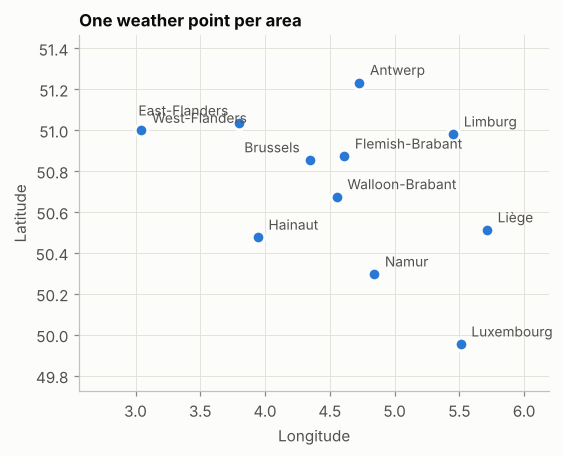

In [3]:
# The sampling point for each area
points = wx.groupby("region")[["latitude", "longitude"]].first()
fig, ax = plt.subplots(figsize=(6.2, 4.2))
ax.scatter(points["longitude"], points["latitude"], s=70, color=BLUE, zorder=3, edgecolor=SURFACE, linewidth=2)
for name, r in points.iterrows():
    left = name in ("Brussels", "East-Flanders")
    ax.annotate(name, (r["longitude"], r["latitude"]), xytext=(-7 if left else 7, 5), textcoords="offset points",
                ha="right" if left else "left", fontsize=9, color=INK2)
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("One weather point per area")
ax.set_aspect(1.58)   # roughly equal distances at 50.5°N
ax.margins(0.18)
plt.show()

## 2. Quality checks

Three questions: is every hour present, are any values missing, and are the values physically possible?

In [4]:
expected = int((wx["datetime_utc"].max() - wx["datetime_utc"].min()) / pd.Timedelta("1h")) + 1
per_area = wx.groupby("region").size()
print(f"Hours per area: expected {expected:,}, found {per_area.min():,} to {per_area.max():,}")
print(f"Duplicate (area, hour) rows: {wx.duplicated(['region', 'datetime_utc']).sum()}")
print(f"Missing values in total: {int(wx[cols].isna().sum().sum())}")

LIMITS = {   # column: (lowest plausible, highest plausible) for Belgium
    "ghi_wm2": (0, 1100), "direct_wm2": (0, 1000), "diffuse_wm2": (0, 700), "dni_wm2": (0, 1100),
    "cloud_total_pct": (0, 100), "cloud_low_pct": (0, 100), "cloud_mid_pct": (0, 100), "cloud_high_pct": (0, 100),
    "temp_c": (-25, 45), "dew_point_c": (-25, 30), "humidity_pct": (10, 100), "pressure_hpa": (900, 1060),
    "precip_mm": (0, 60), "wind_kmh": (0, 130), "wind_gust_kmh": (0, 200), "wind_dir_deg": (0, 360),
}
out = pd.DataFrame({label(c): {"below": int((wx[c] < LIMITS[c][0]).sum()), "above": int((wx[c] > LIMITS[c][1]).sum()),
                               "plausible range": f"{LIMITS[c][0]} to {LIMITS[c][1]}"} for c in cols}).T
out[(out["below"] > 0) | (out["above"] > 0)] if ((out["below"] > 0) | (out["above"] > 0)).any() else "All values inside plausible ranges"

Hours per area: expected 50,976, found 50,976 to 50,976
Duplicate (area, hour) rows: 0
Missing values in total: 0


,below,above,plausible range
Dew point (°C),660,0,-25 to 30
Relative humidity (%),660,0,10 to 100


In [5]:
# When do the implausible values occur? Flag them, list the days, then blank them out.
flag = pd.Series(False, index=wx.index)
for c in cols:
    flag |= (wx[c] < LIMITS[c][0]) | (wx[c] > LIMITS[c][1])
print(f"Rows with at least one implausible value: {flag.sum():,} ({flag.mean():.2%})")

if flag.any():
    bad_cols = [c for c in cols if ((wx[c] < LIMITS[c][0]) | (wx[c] > LIMITS[c][1])).any()]
    days = wx[flag].groupby(wx.loc[flag, "datetime_utc"].dt.date).agg(rows=("region", "size"), areas=("region", "nunique"))
    print(f"Affected variables: {[VARIABLES[c][0] for c in bad_cols]}")
    display(days)
    for c in bad_cols:
        wx.loc[(wx[c] < LIMITS[c][0]) | (wx[c] > LIMITS[c][1]), c] = np.nan
    print("These values are now set to missing in this notebook. Do the same in the modelling notebook.")

Rows with at least one implausible value: 660 (0.12%)
Affected variables: ['Dew point', 'Relative humidity']


,rows,areas
datetime_utc,,
2024-06-26,264,11
2024-06-27,264,11
2024-06-28,132,11


These values are now set to missing in this notebook. Do the same in the modelling notebook.


In [6]:
# Physics checks on the sunlight variables
night = wx[wx["datetime_utc"].dt.hour.isin([23, 0, 1])]
gap = (wx["direct_wm2"] + wx["diffuse_wm2"] - wx["ghi_wm2"]).abs()
print(f"Irradiance above zero around midnight UTC: {(night['ghi_wm2'] > 0).mean():.2%} of rows")
print(f"Direct + diffuse against global irradiance: largest gap {gap.max():.1f} W/m²")
print(f"Hours where a cloud layer exceeds total cloud by more than 1 point: "
      f"{(wx[['cloud_low_pct', 'cloud_mid_pct', 'cloud_high_pct']].max(axis=1) > wx['cloud_total_pct'] + 1).mean():.2%}")
if "wind_gust_kmh" in wx:
    print(f"Hours where gusts are below mean wind speed: {(wx['wind_gust_kmh'] < wx['wind_kmh'] - 0.5).mean():.2%}")
if "dew_point_c" in wx:
    print(f"Hours where dew point is above air temperature: {(wx['dew_point_c'] > wx['temp_c'] + 0.5).mean():.2%}")

Irradiance above zero around midnight UTC: 0.00% of rows
Direct + diffuse against global irradiance: largest gap 0.1 W/m²
Hours where a cloud layer exceeds total cloud by more than 1 point: 1.27%
Hours where gusts are below mean wind speed: 0.04%
Hours where dew point is above air temperature: 0.00%


## 3. Distribution of each variable

Sunlight variables are shown for daylight hours only, since half of all hours are zero. Precipitation is shown for wet hours only, for the same reason.

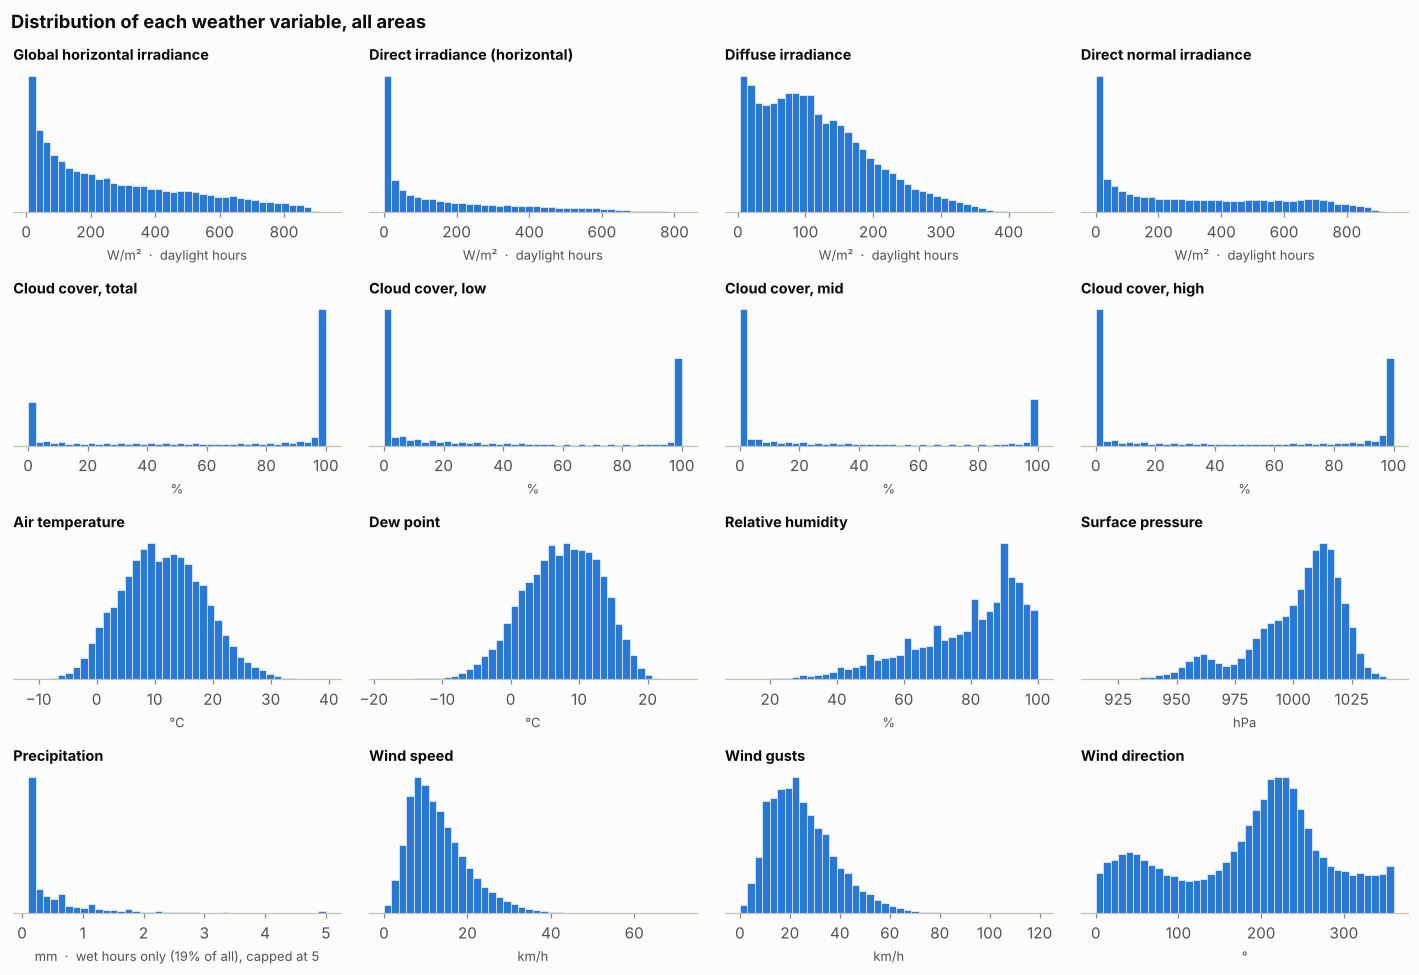

In [7]:
day = wx[wx["ghi_wm2"] > 5]
fig, axes = plt.subplots(4, 4, figsize=(13, 9))
for ax, c in zip(axes.ravel(), cols):
    data = wx[c].dropna()
    note = ""
    if VARIABLES[c][2] == "Sunlight":
        data, note = day[c].dropna(), "daylight hours"
    elif c == "precip_mm":
        data, note = data[data > 0].clip(upper=5), f"wet hours only ({(wx[c] > 0).mean():.0%} of all), capped at 5"
    ax.hist(data, bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.4)
    ax.set_title(VARIABLES[c][0], fontsize=9.5)
    ax.set_xlabel(f"{VARIABLES[c][1]}" + (f"  ·  {note}" if note else ""), fontsize=8.5)
    ax.set_yticks([]); ax.grid(False)
    ax.spines["left"].set_visible(False)
for ax in axes.ravel()[len(cols):]:
    ax.set_visible(False)
fig.suptitle("Distribution of each weather variable, all areas", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
plt.show()

## 4. Patterns over time

### 4.1 Month by month

Each panel has its own scale. Look for the yearly cycle and for anything that breaks it.

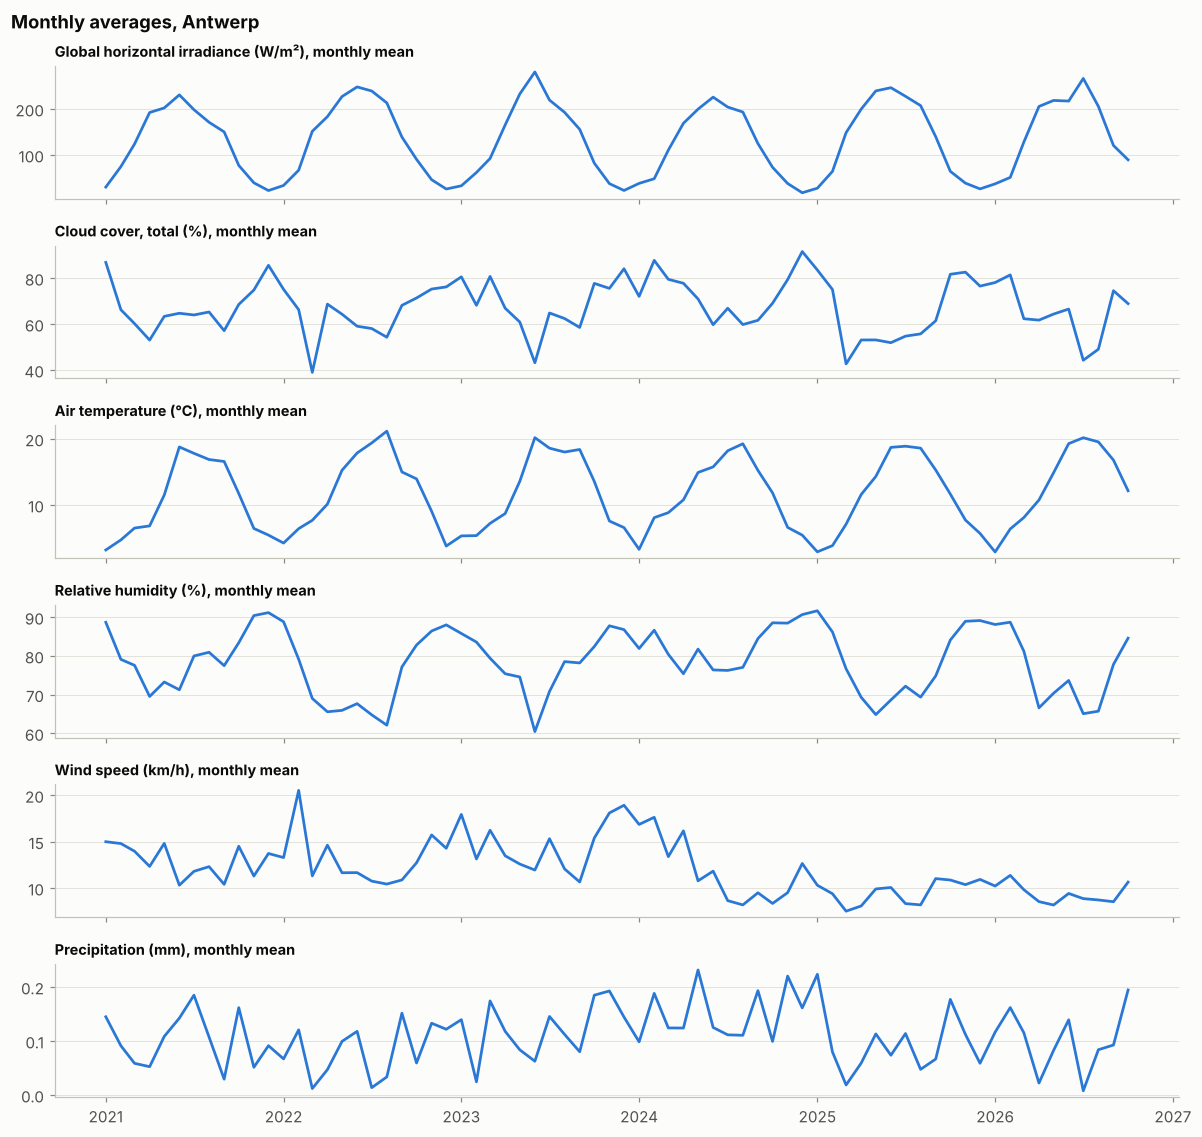

In [8]:
one = wx[wx["region"] == PROVINCE].set_index("datetime_utc")
monthly = one[cols].resample("MS").mean()
panels = ["ghi_wm2", "cloud_total_pct", "temp_c", "humidity_pct", "wind_kmh", "precip_mm"]
panels = [c for c in panels if c in cols]

fig, axes = plt.subplots(len(panels), 1, figsize=(11, 1.75 * len(panels)), sharex=True)
for ax, c in zip(axes, panels):
    ax.plot(monthly.index, monthly[c], color=BLUE)
    ax.set_title(label(c) + ", monthly mean", fontsize=9.5)
    ax.grid(axis="x", visible=False)
axes[-1].xaxis.set_major_locator(mdates.YearLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle(f"Monthly averages, {PROVINCE}", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
plt.show()

### 4.2 Irradiance by month and hour

This is the shape the model has to learn before clouds enter: long bright days in summer, short dim days in winter.

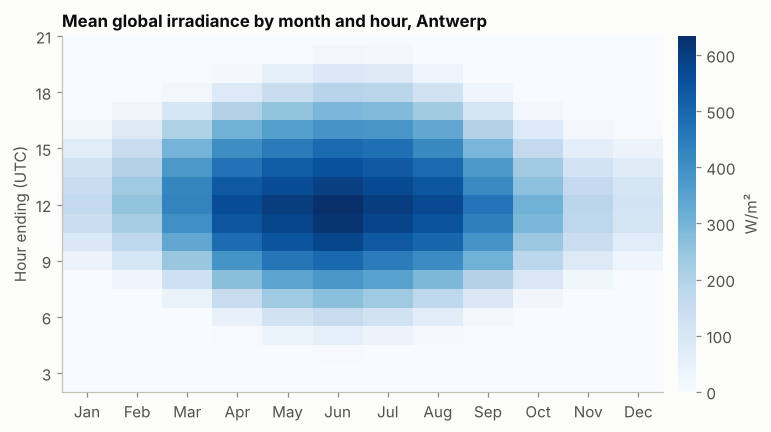

In [9]:
grid = one.pivot_table(index=one.index.hour, columns=one.index.month, values="ghi_wm2", aggfunc="mean")
fig, ax = plt.subplots(figsize=(8.5, 4.2))
im = ax.imshow(grid.values, aspect="auto", origin="lower", cmap="Blues", extent=[0.5, 12.5, -0.5, 23.5])
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_yticks(range(0, 24, 3)); ax.set_ylim(2, 21)
ax.set_ylabel("Hour ending (UTC)")
ax.set_title(f"Mean global irradiance by month and hour, {PROVINCE}")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.02); cb.set_label("W/m²"); cb.outline.set_visible(False)
plt.show()

### 4.3 Cloud cover through the year

Cloud is what makes solar hard to forecast. The share of overcast hours shows how often the model faces its hardest case.

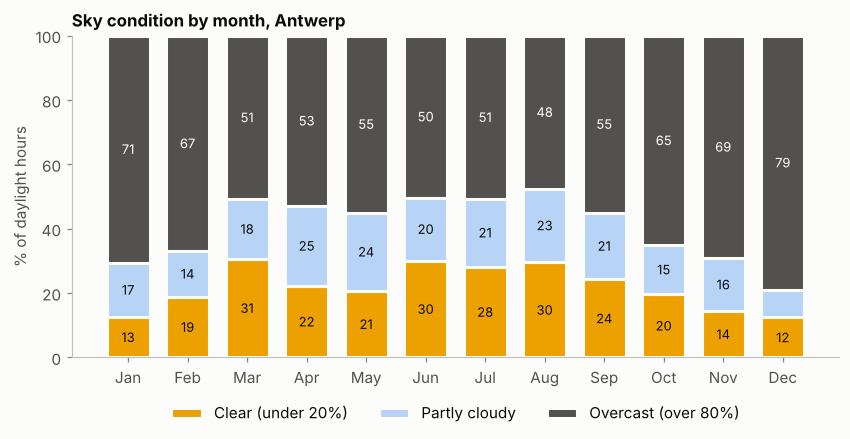

In [10]:
dl = one[one["ghi_wm2"] > 5]
share = pd.DataFrame({
    "Clear (under 20%)": (dl["cloud_total_pct"] < 20).groupby(dl.index.month).mean(),
    "Partly cloudy": ((dl["cloud_total_pct"] >= 20) & (dl["cloud_total_pct"] <= 80)).groupby(dl.index.month).mean(),
    "Overcast (over 80%)": (dl["cloud_total_pct"] > 80).groupby(dl.index.month).mean(),
}) * 100

fig, ax = plt.subplots(figsize=(9, 3.8))
bottom = np.zeros(len(share))
for (name, vals), color in zip(share.items(), [YELLOW, BLUE_LIGHT, INK2]):
    ax.bar(share.index, vals, bottom=bottom, color=color, width=0.72, edgecolor=SURFACE, linewidth=2, label=name)
    for x, (b, v) in zip(share.index, zip(bottom, vals)):
        if v > 9:
            ax.text(x, b + v / 2, f"{v:.0f}", ha="center", va="center", fontsize=8.5,
                    color="white" if color == INK2 else INK)
    bottom += vals.values
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("% of daylight hours"); ax.set_ylim(0, 100)
ax.set_title(f"Sky condition by month, {PROVINCE}")
ax.grid(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
plt.show()

### 4.4 Is the data consistent over time?

The archive stitches together forecasts from whichever weather model Open-Meteo used at the time. If that model changed, a variable can shift level for reasons unrelated to the weather. A model trained on the earlier years would then see slightly different inputs in the later ones.

The test: a 12-month rolling mean removes the seasons, so each line should be roughly flat. A step is a warning sign. The table compares two season-balanced windows of two years each.

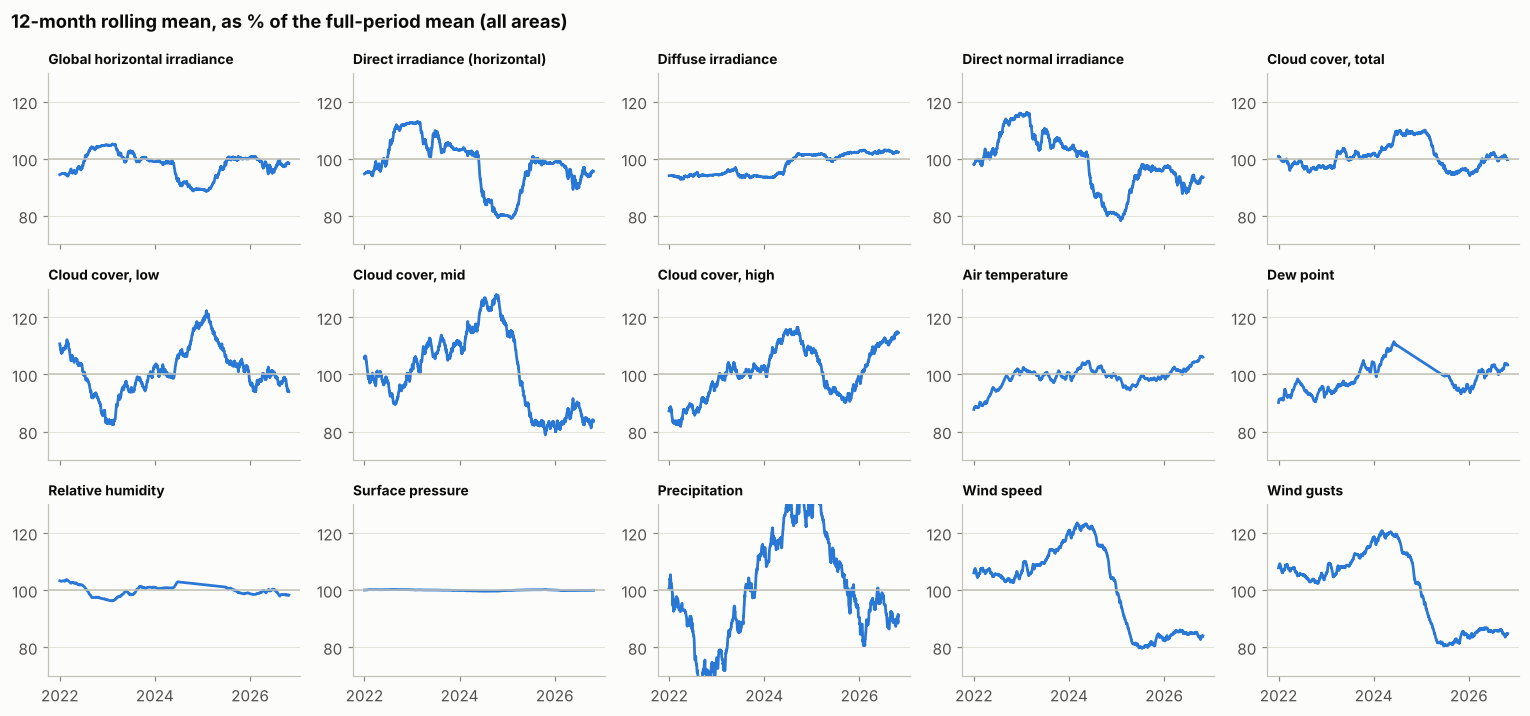

,Jul 2022 to Jun 2024,Jul 2024 to Jun 2026,change %
Wind speed (km/h),15.02,10.69,-28.85
Wind gusts (km/h),28.57,20.87,-26.96
"Cloud cover, mid (%)",34.37,26.09,-24.11
Direct normal irradiance (W/m²),147.94,135.60,-8.34
Direct irradiance (horizontal) (W/m²),76.28,72.46,-5.01
Diffuse irradiance (W/m²),55.89,58.64,4.92
"Cloud cover, total (%)",70.53,67.27,-4.63
Precipitation (mm),0.12,0.12,-3.26
"Cloud cover, high (%)",46.17,44.74,-3.09
"Cloud cover, low (%)",37.93,39.08,3.04


In [11]:
allarea = wx.groupby("datetime_utc")[cols].mean()
roll = allarea.rolling(24 * 365, min_periods=24 * 365).mean()
check = [c for c in cols if c != "wind_dir_deg"]

fig, axes = plt.subplots(3, 5, figsize=(14, 6.6), sharex=True)
for ax, c in zip(axes.ravel(), check):
    r = roll[c].dropna()
    ax.plot(r.index, r / allarea[c].mean() * 100, color=BLUE)
    ax.axhline(100, color=AXIS, linewidth=1)
    ax.set_ylim(70, 130)
    ax.set_title(VARIABLES[c][0], fontsize=9)
    ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.grid(axis="x", visible=False)
for ax in axes.ravel()[len(check):]:
    ax.set_visible(False)
fig.suptitle("12-month rolling mean, as % of the full-period mean (all areas)", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fig.tight_layout()
plt.show()

before = allarea.loc["2022-07-01":"2024-06-30", check].mean()
after = allarea.loc["2024-07-01":"2026-06-30", check].mean()
shift = pd.DataFrame({"Jul 2022 to Jun 2024": before, "Jul 2024 to Jun 2026": after,
                      "change %": (after / before - 1) * 100})
shift.index = [label(c) for c in check]
shift.sort_values("change %", key=abs, ascending=False)

Weather does differ from one two-year window to the next, so small changes are normal. A change of 20% or more in a variable such as wind speed, appearing as a step in the chart, points to a change in the source model. If you see one, either leave that variable out, or check whether the model's results depend on it.

## 5. A sample week, all variables

One week at hourly detail. Each panel groups variables that share a unit, so no panel has two scales.

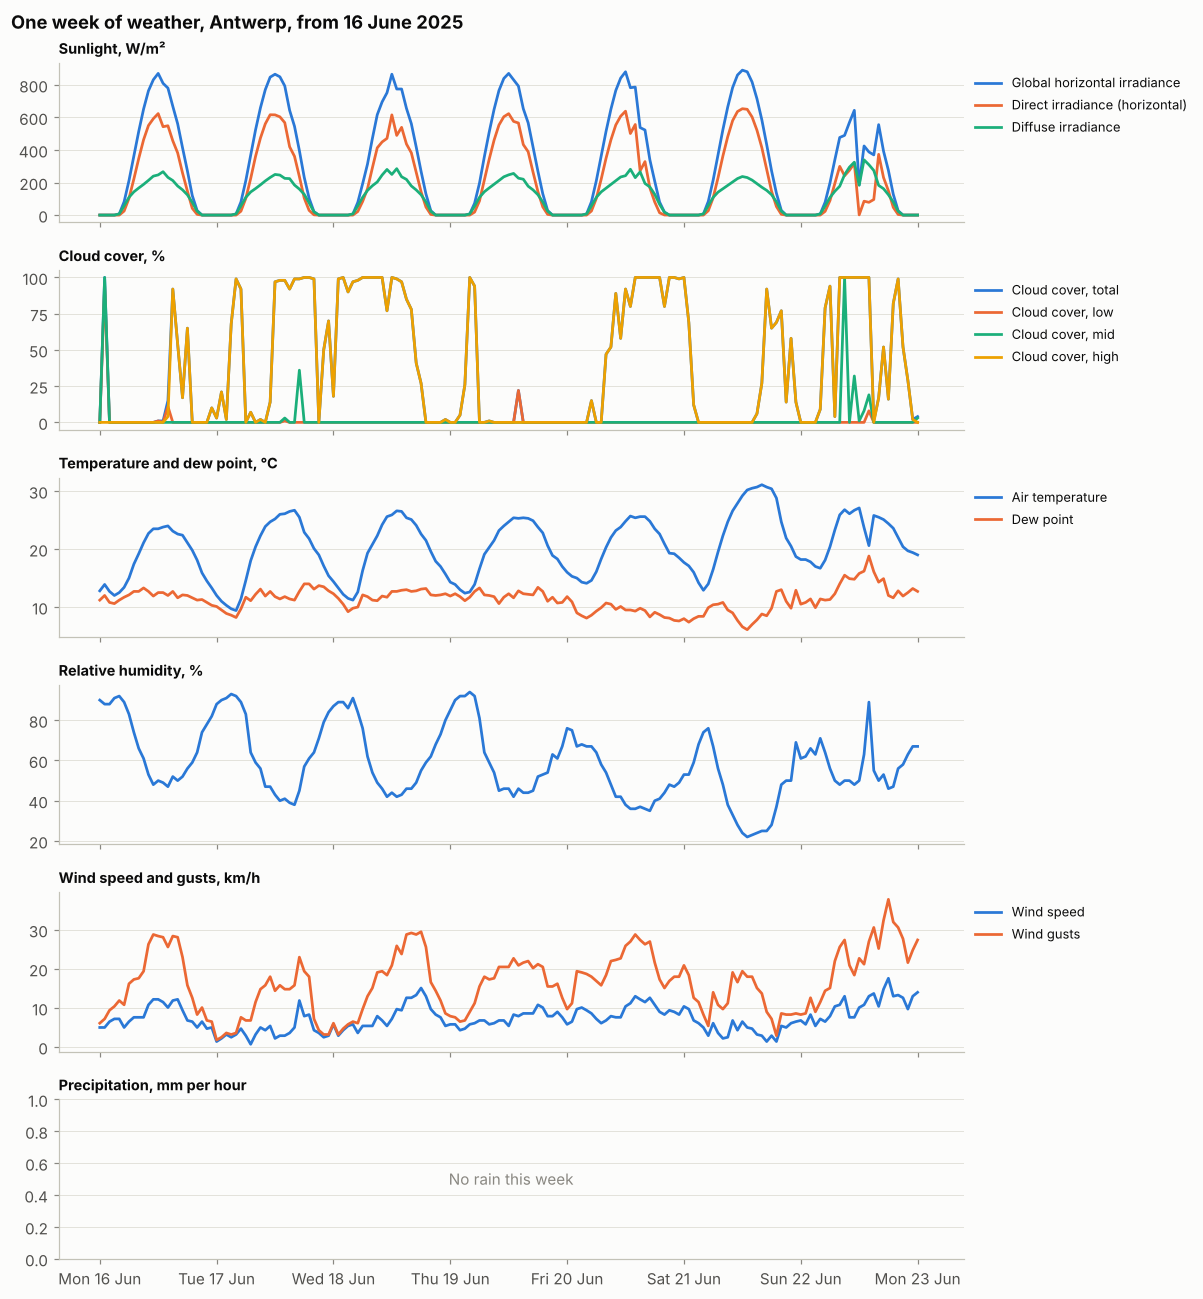

In [12]:
start = pd.Timestamp(WEEK_START, tz="UTC")
week = one.loc[start: start + pd.Timedelta(days=7)]

groups = [
    ("Sunlight, W/m²", ["ghi_wm2", "direct_wm2", "diffuse_wm2"]),
    ("Cloud cover, %", ["cloud_total_pct", "cloud_low_pct", "cloud_mid_pct", "cloud_high_pct"]),
    ("Temperature and dew point, °C", ["temp_c", "dew_point_c"]),
    ("Relative humidity, %", ["humidity_pct"]),
    ("Wind speed and gusts, km/h", ["wind_kmh", "wind_gust_kmh"]),
    ("Precipitation, mm per hour", ["precip_mm"]),
]
groups = [(t, [c for c in cs if c in cols]) for t, cs in groups]
groups = [(t, cs) for t, cs in groups if cs]
colors = [BLUE, ORANGE, AQUA, YELLOW]

fig, axes = plt.subplots(len(groups), 1, figsize=(11, 2.0 * len(groups)), sharex=True)
for ax, (title, cs) in zip(axes, groups):
    if cs == ["precip_mm"]:
        ax.bar(week.index, week["precip_mm"], width=1 / 24, color=BLUE, align="edge")
        ax.set_ylim(0, max(1.0, week["precip_mm"].max() * 1.15))
        if week["precip_mm"].sum() == 0:
            ax.text(0.5, 0.5, "No rain this week", transform=ax.transAxes, ha="center", va="center", color=MUTED)
    else:
        for c, color in zip(cs, colors):
            ax.plot(week.index, week[c], color=color, label=VARIABLES[c][0])
        if len(cs) > 1:
            ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8.5)
    ax.set_title(title, fontsize=9.5)
    ax.grid(axis="x", visible=False)
axes[-1].xaxis.set_major_locator(mdates.DayLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b"))
fig.suptitle(f"One week of weather, {PROVINCE}, from {start:%d %B %Y}", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
plt.show()

## 6. Differences between provinces

The final model pools all eleven areas. These charts show how alike they are, which is what makes pooling reasonable, and where they differ.

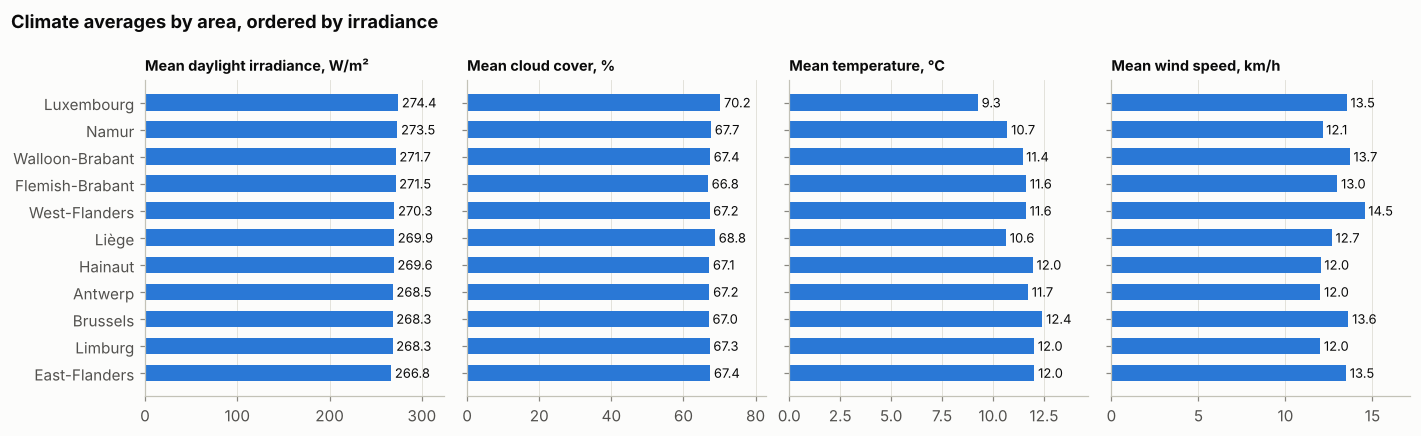

In [13]:
by_region = wx.groupby("region")[cols].mean()
by_region["ghi_daylight"] = wx[wx["ghi_wm2"] > 5].groupby("region")["ghi_wm2"].mean()
show = [("ghi_daylight", "Mean daylight irradiance, W/m²"), ("cloud_total_pct", "Mean cloud cover, %"),
        ("temp_c", "Mean temperature, °C"), ("wind_kmh", "Mean wind speed, km/h")]

fig, axes = plt.subplots(1, 4, figsize=(13, 4), sharey=True)
order = by_region["ghi_daylight"].sort_values().index
for ax, (c, title) in zip(axes, show):
    v = by_region.loc[order, c]
    ax.barh(order, v, color=BLUE, height=0.62)
    for y, x in enumerate(v):
        ax.text(x, y, f" {x:.1f}", va="center", fontsize=8.5, color=INK)
    lo, hi = v.min(), v.max()
    ax.set_xlim(0, hi * 1.18)
    ax.set_title(title, fontsize=9.5)
    ax.grid(axis="y", visible=False)
fig.suptitle("Climate averages by area, ordered by irradiance", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
plt.show()

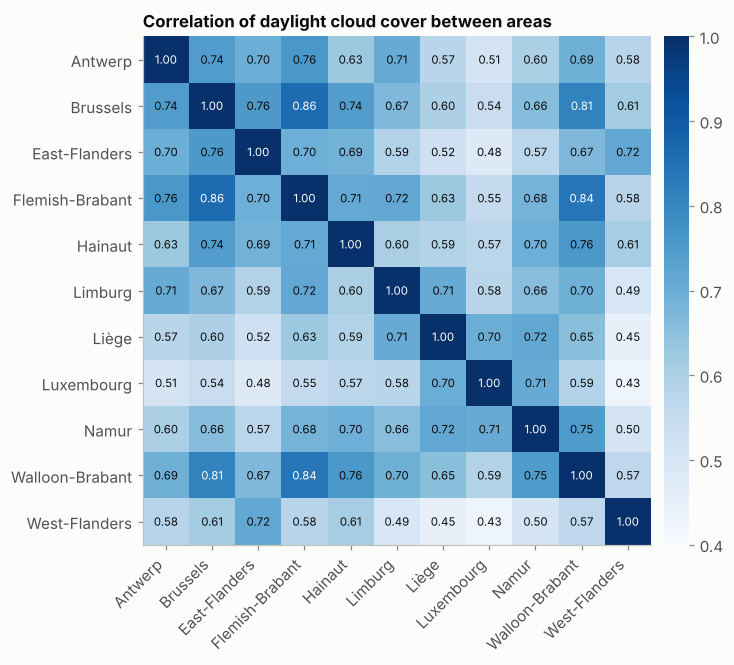

Most alike:  Brussels and Flemish-Brabant (0.86)
Least alike: Luxembourg and West-Flanders (0.43)


In [14]:
# How closely do the areas move together? Correlation of hourly cloud cover between areas.
# (Cloud is used, not irradiance: irradiance correlates near 1 everywhere just because the sun rises for all.)
wide = wx[wx["ghi_wm2"] > 5].pivot(index="datetime_utc", columns="region", values="cloud_total_pct")
corr = wide.corr()

fig, ax = plt.subplots(figsize=(7.4, 6))
im = ax.imshow(corr.values, cmap="Blues", vmin=0.4, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right"); ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if corr.values[i, j] > 0.8 else INK)
ax.set_title("Correlation of daylight cloud cover between areas")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.02); cb.outline.set_visible(False)
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, bool), k=1)).stack()
print(f"Most alike:  {pairs.idxmax()[0]} and {pairs.idxmax()[1]} ({pairs.max():.2f})")
print(f"Least alike: {pairs.idxmin()[0]} and {pairs.idxmin()[1]} ({pairs.min():.2f})")

## 7. How the features relate to each other

Correlation between the raw features in daylight hours, all areas. Two uses:

- **Redundancy.** Pairs near +1 or -1 carry almost the same information. Tree models cope with that, but linear models become unstable and feature importance gets split between the twins.
- **Report material.** This supports the data description section.

Wind direction is left out, since it is a circular variable (359° and 1° are neighbours) and an ordinary correlation would mislead.

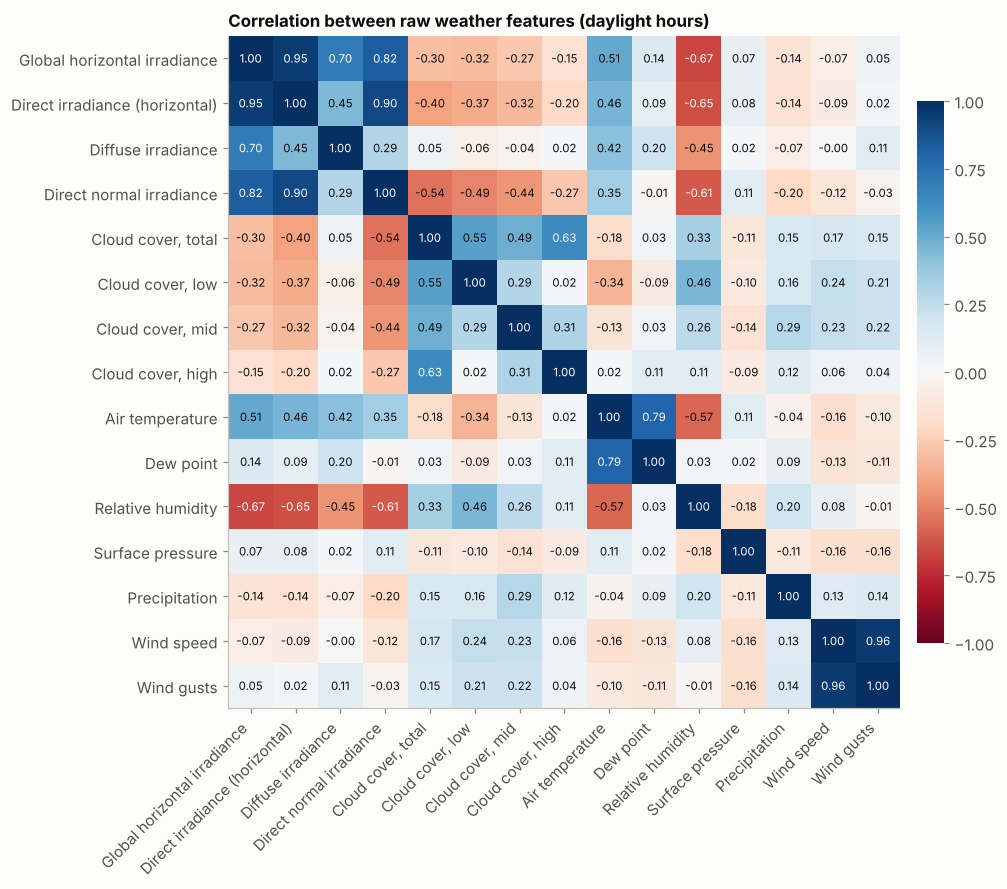

Pairs with correlation beyond ±0.8:
  Wind speed  and  Wind gusts:  +0.96
  Global horizontal irradiance  and  Direct irradiance (horizontal):  +0.95
  Direct irradiance (horizontal)  and  Direct normal irradiance:  +0.90
  Global horizontal irradiance  and  Direct normal irradiance:  +0.82


In [15]:
feat = [c for c in cols if c != "wind_dir_deg"]
fc = wx.loc[wx["ghi_wm2"] > 5, feat].corr()
names = [VARIABLES[c][0] for c in feat]

fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(fc.values, cmap="RdBu", vmin=-1, vmax=1)
ax.set_xticks(range(len(feat)), names, rotation=45, ha="right"); ax.set_yticks(range(len(feat)), names)
for i in range(len(feat)):
    for j in range(len(feat)):
        v = fc.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5, color="white" if abs(v) > 0.6 else INK)
ax.set_title("Correlation between raw weather features (daylight hours)")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.02, shrink=0.8); cb.outline.set_visible(False)
plt.show()

pairs = fc.where(np.triu(np.ones(fc.shape, bool), k=1)).stack()
strong = pairs[pairs.abs() > 0.8].sort_values(key=abs, ascending=False)
print("Pairs with correlation beyond ±0.8:")
for (a, b), v in strong.items():
    print(f"  {VARIABLES[a][0]}  and  {VARIABLES[b][0]}:  {v:+.2f}")

## What to take from this

Fill this in from the outputs above:

- **Completeness:** hours present, missing values, and any days with implausible values (section 2).
- **Seasonality:** the size of the summer to winter swing in irradiance, and how often the sky is overcast (section 4).
- **Pooling:** how alike the provinces are (section 6).
- **Redundancy:** which features duplicate each other (section 7).

**Reminder on what this data is.** It comes from Open-Meteo's archive of past forecasts, which stitches together the first hours of each model run. It is closer to the weather that happened than a true day-ahead forecast would be.